------------------------------------------------
['air', 'lxe', 'lxe2', 'cf4', 'green', 'red']
style object members: 	 ['col', 'ls', 'name', 'printMembers']


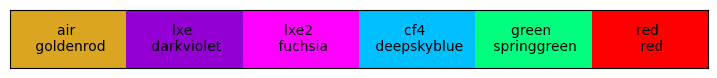

In [53]:
import matplotlib.pyplot as plt
import copy
import numpy as np
import pandas as pd

import json

import sys
sys.path.append('../')
from DAAPS_TOOLKIT.GenPaths import *

import PDEModel.MathEquations as ME
# from PDEModel.OpticsDataLoader import *
import PDEModel.PDEStyle as MS
import PDEModel.PhotonInfo as PI # this calls DataLoader when defining init
import PNJunction as PNJ

import FittingFunctions as FFs

# rad2deg = 180/np.pi

MS.ShowMyStyles() # for colors
ms = MS.MyStyleSet() # object to use like
ms.SetMPLcolors() # turn off with "off" option

## should enforce the 'table' here. use 1-R for oblique angles, and then use real_theta3 for oblique angles and wlen < 155nm

# only doing down to 160 nm
# for wlens below that, should use T equation but with real theta_3 (approximation)

In [54]:
# dhFranta = OpticsData(siDataPath=os.path.join(OPTICS_DATA_PATH, "Franta_data", "Franta-150K.txt"))
dhFranta = None
# fixedPars_Boring = {"quantum": False, "smoothSigma": 9/2.335, "dh":dhFranta, "window":True}

with open("input_systematics.json", 'r') as file:
    json_systematic = json.load(file)

saveFlag = True
configName = "_defaultData_globalPar_145K_june12"
window = False
shadowingH = None ## FBK

### HPK specifics ###
# FF1 = json_systematic["HPK_VUV4"]["input_systematics"]["FF"]
# tOxide_values = json_systematic["HPK_VUV4"]["input_systematics"]["tOxide"]
# ttGood = tOxide_values[0] # good thickness in nm
# vOffset = json_systematic["HPK_VUV4"]["Voffset"][1]
# pnParameters = json_systematic["HPK_VUV4"]["fit_parameters"]
# pnParameters = {key: pnParameters[key][0] for key in pnParameters}

## HPK
window = True
FF1 = 0.6 ## HPK
ttGood = 17.2 #nm
# shadowingH = 2.5/50 ## HPK

devName = "HPK-VUV4_noWindow_17nmOxide" + configName
pnParameters = {"dp_star": 1.03, "Xpn": 2.35e3, "dw_star":13.6e3, "Ve":1.80, "Vh":16.76}
mediumProduction = "cf4"

### comment out this section to do HPK ###
######### FBK
# window = False
# FF1 = 0.8
# ttGood = 1360
# devName = "FBK-LF_1360nmOxide" + configName
# pnParameters = {"dp_star": 0.96, "Xpn": 510, "dw_star":8.33e3, "Ve":1.83, "Vh":18.77}
# ## comment out these 5 lines if using HPK_VUV4

#########
fixedPars_parametrized = {"Ae":1.0, "Ah":1.0}
fixedPars_physics = {"FF": FF1, "Temperature": 145, "tOxide":ttGood}

### keep this
opticsName = "optics_" + devName + ".csv"
internalName = "internalPDE_" + devName + ".csv"
onlyWname = "absorptionOnly_" + devName + ".csv"

# Define the range of angles and wavelengths
wlenRange = np.arange(155, 1100, 2.5)
angles = np.arange(0, 90, 2.5)

print(pnParameters)
# print(fixedPars_Boring)
print(fixedPars_physics)
print(fixedPars_parametrized)

{'dp_star': 1.03, 'Xpn': 2350.0, 'dw_star': 13600.0, 'Ve': 1.8, 'Vh': 16.76}
{'FF': 0.6, 'Temperature': 145, 'tOxide': 17.2}
{'Ae': 1.0, 'Ah': 1.0}


/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/matplotlib/cbook.py:1762: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/matplotlib/cbook.py:1398: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


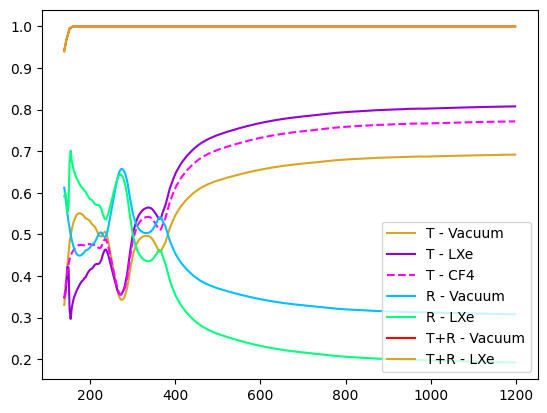

In [55]:
### Make the Transmission 2d table ###
wlenRange = np.arange(140, 1200, 2.5)
pi = PI.PhotonInfo(wlenRange, 0, dataHelper=None, mediumStr="vacuum")
picf4 = PI.PhotonInfo(wlenRange, 0, dataHelper=None, mediumStr="vacuum")
picf4.nVacuum = 1.24 + 0j
picf4.BuildThetas()

tox = 17

piXe = PI.PhotonInfo(wlenRange, 0, dataHelper=None, mediumStr="lxe")

plt.plot(wlenRange, pi.Wave_TotalTransmission(tox), label = "T - Vacuum")

plt.plot(wlenRange, piXe.Wave_TotalTransmission(tox), label = "T - LXe")
plt.plot(wlenRange, picf4.Wave_TotalTransmission(tox), linestyle = "--", label = "T - CF4")

plt.plot(wlenRange, pi.Wave_TotalReflection(tox), label = "R - Vacuum")
plt.plot(wlenRange, piXe.Wave_TotalReflection(tox), label = "R - LXe")

plt.plot(wlenRange, pi.Wave_TotalTransmission(tox) + pi.Wave_TotalReflection(tox), label = "T+R - Vacuum")
plt.plot(wlenRange, piXe.Wave_TotalTransmission(tox) + piXe.Wave_TotalReflection(tox), label = "T+R - LXe")

plt.legend()

In [56]:
# Initialize empty dataframe
df = pd.DataFrame(columns=['wavelength', 'angle', 'transmission_vacuum', 'transmission_Medium', 'reflection_vacuum', 'reflection_Medium'])

# Compute the transmission and reflection for each angle
for angle in angles:
  pi = PI.PhotonInfo(wlenRange, angle, dataHelper=None, mediumStr="vacuum")
  piMedium = PI.PhotonInfo(wlenRange, angle, dataHelper=None, mediumStr=mediumProduction)
  
  if not window:
    reflection_vacuum = pi.Wave_TotalReflection(ttGood) # z3(x, fixed y)
    reflection_Medium = piMedium.Wave_TotalReflection(ttGood) # z4(x, fixed y)
    # transmission_vacuum = pi.Wave_TotalTransmission(ttGood) # z1(x, fixed y)
    # transmission_Medium = piMedium.Wave_TotalTransmission(ttGood) # z2(x, fixed y)
    transmission_vacuum = 1 - reflection_vacuum # z1(x, fixed y)
    transmission_Medium = 1 - reflection_Medium # z2(x, fixed y)
    
    ## not doing shadowing here because it impacts FF in reality. so should do that in initial FF call
    ## in markov chain MC style (dont do shadowing in lookup table)
    # relative_W = FFs.W_from_FF(FF1)
    # if shadowingH is not None:
    #   # FF_theta = FF1 - 2 * FFs.FF_theta_relative_shadow(theta = theta, W = relative_W, H = relativeH)
    #   subtractFromFF1 = FFs.FF_theta_relative_shadow(theta = angle, W = relative_W, H = shadowingH)
      
    ## not this because 
  elif window:
    transmission_vacuum = pi.T_total_windowAndOxide(ttGood, absorption=True) # z1(x, fixed y)
    transmission_Medium = piMedium.T_total_windowAndOxide(ttGood, absorption=True) # z2(x, fixed y)
    # reflection_vacuum = 1 - transmission_vacuum
    # reflection_Medium = 1 - transmission_Medium
    reflection_vacuum = pi.R_total_windowAndOxide(ttGood, absorption=True) # z3(x, fixed y)
    reflection_Medium = piMedium.R_total_windowAndOxide(ttGood, absorption=True) # z4(x, fixed y)
  
  # Build dataframe here. This will have x array, fixed y value, and the 4 z values for each x value
  temp_df = pd.DataFrame({
    'wavelength': wlenRange,
    'angle': angle,
    'transmission_vacuum': transmission_vacuum.real,
    'transmission_'+str(mediumProduction): transmission_Medium.real,
    'reflection_vacuum': reflection_vacuum.real,
    'reflection_'+str(mediumProduction): reflection_Medium.real
  })
  
  # Concatenate to previous dataframe
  df = pd.concat([df, temp_df], ignore_index=True)

# Do some reordering or reorganizing of the dataframe if necessary
df = df[['wavelength', 'angle', 'transmission_vacuum', 'transmission_'+str(mediumProduction), 'reflection_vacuum', 'reflection_'+str(mediumProduction)]]

# Reorder the dataframe by wavelength and then by angle
df = df.sort_values(by=['wavelength', 'angle']).reset_index(drop=True)

# Save the dataframe to a CSV file
if saveFlag:
  df.to_csv('outputs/modelOutputs_df_sim/' + opticsName, index=False)

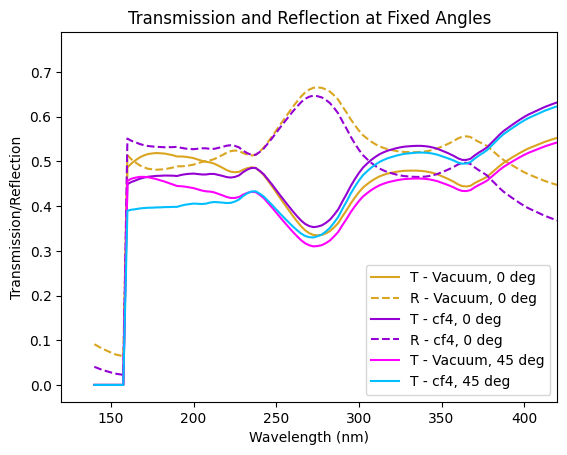

In [57]:
## plot some example curves at fixed angles

plt.plot(wlenRange, df.loc[df['angle'] == 0]['transmission_vacuum'], label = "T - Vacuum, 0 deg", color = ms.GetNextColor())
plt.plot(wlenRange, df.loc[df['angle'] == 0]['reflection_vacuum'], linestyle = "--",  label = "R - Vacuum, 0 deg", color = ms.GetNextColor(1))

plt.plot(wlenRange, df.loc[df['angle'] == 0]['transmission_'+str(mediumProduction)], label = f"T - {mediumProduction}, 0 deg", color = ms.GetNextColor())
plt.plot(wlenRange, df.loc[df['angle'] == 0]['reflection_'+str(mediumProduction)], linestyle = "--", label = f"R - {mediumProduction}, 0 deg", color = ms.GetNextColor(1))

plt.plot(wlenRange, df.loc[df['angle'] == 45]['transmission_vacuum'], label = "T - Vacuum, 45 deg", color = ms.GetNextColor())
plt.plot(wlenRange, df.loc[df['angle'] == 45]['transmission_'+str(mediumProduction)], label = f"T - {mediumProduction}, 45 deg", color = ms.GetNextColor())


plt.xlabel('Wavelength (nm)')
plt.ylabel('Transmission/Reflection')
plt.title('Transmission and Reflection at Fixed Angles')
plt.legend(loc = "lower right")

plt.xlim(120, 420)
plt.show()

---
Now do internal PDE. 

temperature scaling not tested/validated below 300nm, be careful
PDE becomes affected by charge carrier freezeout below 150k, photo absorption alone may not be enough.


/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/matplotlib/cbook.py:1762: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/matplotlib/cbook.py:1398: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


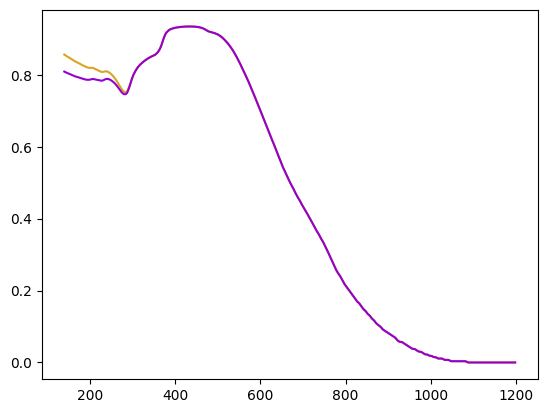

In [58]:

pnParameters

pnJunction = PNJ.PNJunction(dp_star = pnParameters["dp_star"], Xpn = pnParameters["Xpn"], dw_star = pnParameters["dw_star"])
photon = PI.PhotonInfo(wlenRange, 0, dataHelper=None, materialTemp=fixedPars_physics["Temperature"])

def wrapped_internalPDE(pnJunction, photon, voltage, quantum=True):
    Ae = fixedPars_parametrized["Ae"]
    Ah = fixedPars_parametrized["Ah"]
    pe = ME.Pcar_parametrized(voltage, Vc=pnParameters["Ve"], A=Ae)
    if quantum:
        qpe = ME.QuantumPe(photon.wlen, pe, cutinWl=300, power=0.75)
    else:
        qpe = pe
    ph = ME.Pcar_parametrized(voltage, Vc=pnParameters["Vh"], A=Ah)
    Wp, Wn = pnJunction.calcW_both(photon)
    return Wp*qpe + Wn*ph

# plt.plot(wlenRange, wrapped_internalPDE(pnJunction, photon, 5))
plt.plot(wlenRange, wrapped_internalPDE(pnJunction, photon, 5))
plt.plot(wlenRange, wrapped_internalPDE(pnJunction, photon, 5, quantum = False))

In [59]:
# Define the range of angles and wavelengths
voltages = np.arange(2.5, 6, 0.5)
##insert 4.36 V in there
voltages = np.sort(np.append(voltages, [4.36, 7, 8]))

photonInternal = PI.PhotonInfo(wlenRange, 0, dataHelper=None)

# Initialize empty dataframe
df_internal = pd.DataFrame(columns=['wavelength', 'voltage', 'internalPDE'])

# Compute the internal PDE for each voltage
for voltage in voltages:
  internal_pde_values = wrapped_internalPDE(pnJunction, photon, voltage)
  
  # Build dataframe here. This will have x array, fixed y value, and the z value for each x value
  temp_df_internal = pd.DataFrame({
    'wavelength': wlenRange,
    'voltage': voltage,
    'internalPDE': internal_pde_values.real
  })
  
  # Concatenate to previous dataframe
  df_internal = pd.concat([df_internal, temp_df_internal], ignore_index=True)

# Do some reordering or reorganizing of the dataframe if necessary
df_internal = df_internal[['wavelength', 'voltage', 'internalPDE']]

# Reorder the dataframe by wavelength and then by voltage
df_internal = df_internal.sort_values(by=['wavelength', 'voltage']).reset_index(drop=True)

# Save the dataframe to a CSV file
if saveFlag:
  df_internal.to_csv('outputs/modelOutputs_df_sim/'+internalName, index=False)

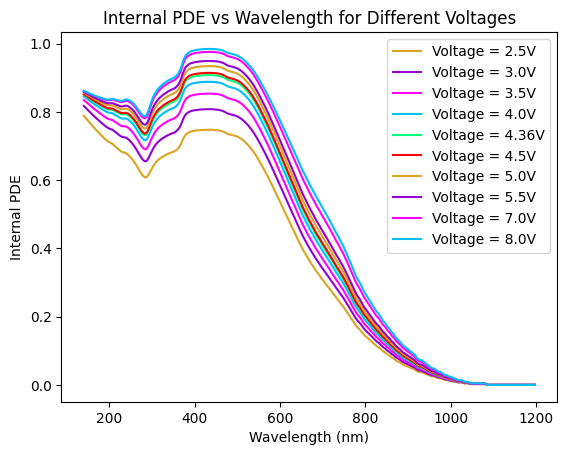

In [60]:
# Plot internal PDE for different voltages
for voltage in voltages[:]:
  plt.plot(wlenRange, df_internal[df_internal['voltage'] == voltage]['internalPDE'], label=f'Voltage = {voltage}V')

plt.xlabel('Wavelength (nm)')
plt.ylabel('Internal PDE')
plt.title('Internal PDE vs Wavelength for Different Voltages')
plt.legend()
plt.show()

# # Plot transmission and reflection for a specific angle
# angle_to_plot = 45
# plt.plot(wlenRange, df_internal.loc[df_internal['angle'] == angle_to_plot]['transmission_vacuum'], label=f'Transmission Vacuum, {angle_to_plot} deg')
# plt.plot(wlenRange, df_internal.loc[df_internal['angle'] == angle_to_plot]['transmission_lxe'], label=f'Transmission LXe, {angle_to_plot} deg')
# plt.plot(wlenRange, df_internal.loc[df_internal['angle'] == angle_to_plot]['reflection_vacuum'], label=f'Reflection Vacuum, {angle_to_plot} deg')
# plt.plot(wlenRange, df_internal.loc[df_internal['angle'] == angle_to_plot]['reflection_lxe'], label=f'Reflection LXe, {angle_to_plot} deg')

# plt.xlabel('Wavelength (nm)')
# plt.ylabel('Transmission/Reflection')
# plt.title(f'Transmission and Reflection at {angle_to_plot} Degrees')
# plt.legend()
# plt.show()

In [61]:
# # now only providing wlen, and user inputs voltage information for 'voltage float precision' iPDE
# photonInternal = PI.PhotonInfo(wlenRange, 0, dataHelper=None)

# # Initialize empty dataframe
# df = pd.DataFrame(columns=['wavelength', 'Wp', 'Wn'])

# # Compute the internal PDE for each voltage
# Wp, Wn = pnJunction.calcW_both(photonInternal)
# # if value less than 0.001, set to 0
# Wp[Wp < 0.001] = 0
# Wn[Wn < 0.001] = 0

# # Build dataframe here. 
# temp_df = pd.DataFrame({
#   'wavelength': wlenRange,
#   'Wp': np.real(Wp),
#   'Wn': np.real(Wn)
# })

# # Concatenate to previous dataframe
# df = pd.concat([df, temp_df], ignore_index=True)

# # Do some reordering or reorganizing of the dataframe if necessary
# df = df[['wavelength', 'Wp', 'Wn']]

# # Reorder the dataframe by wavelength and then by voltage
# df = df.sort_values(by=['wavelength']).reset_index(drop=True)

# # Save the dataframe to a CSV file
# if saveFlag:
#   df.to_csv('outputs/modelOutputs_df_sim/'+onlyWname, index=False)

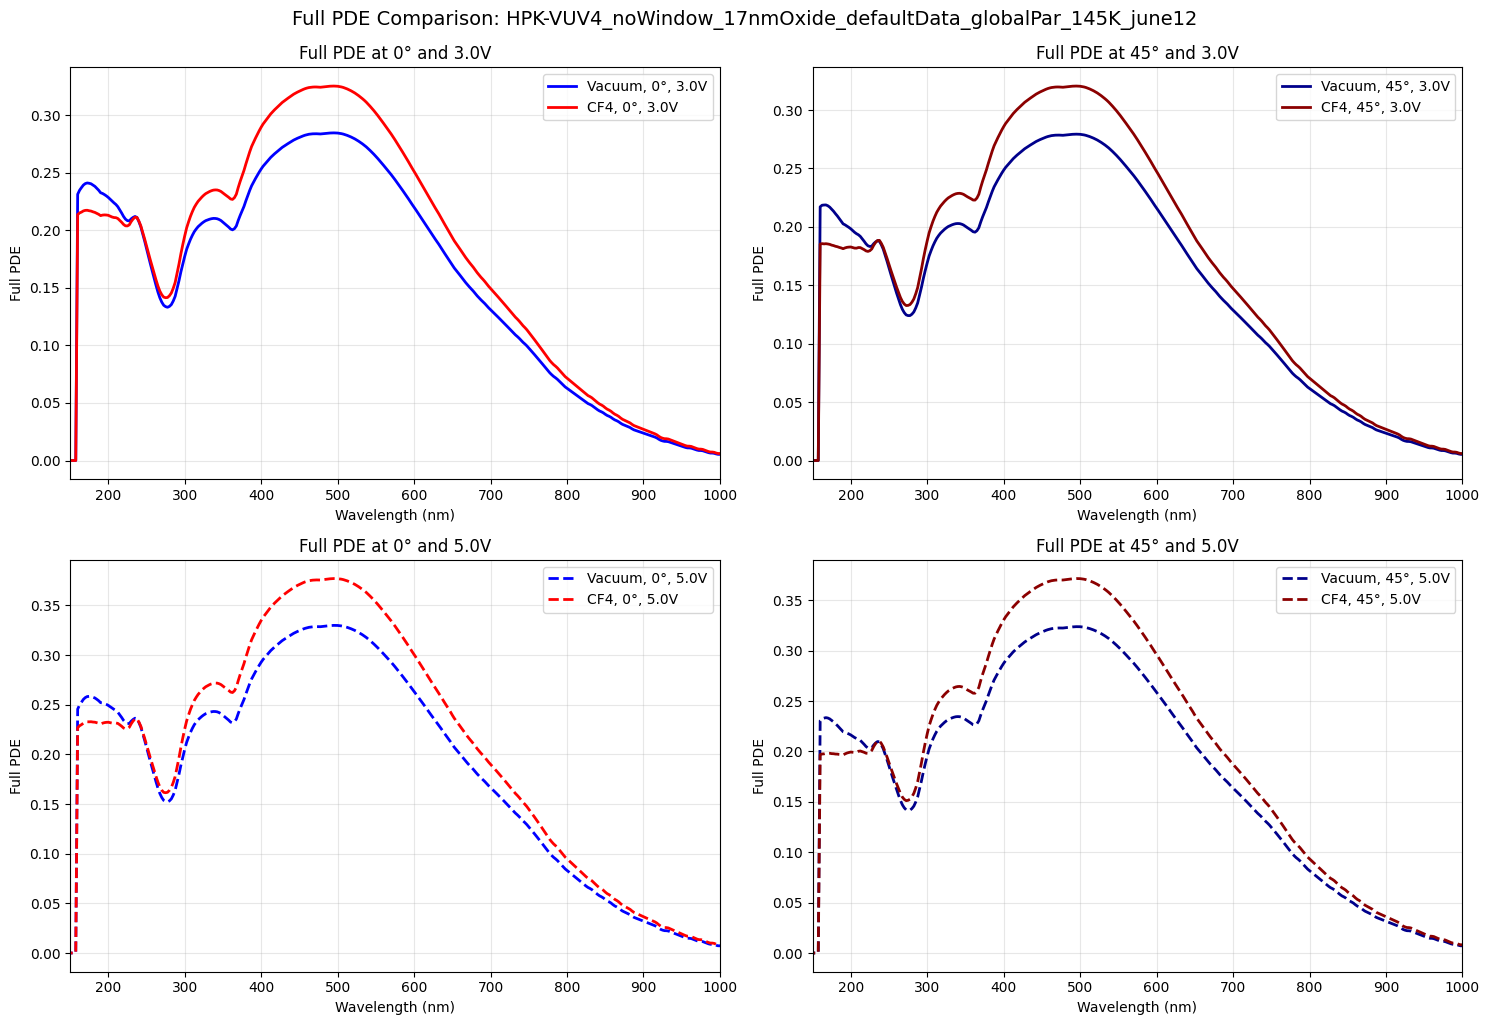

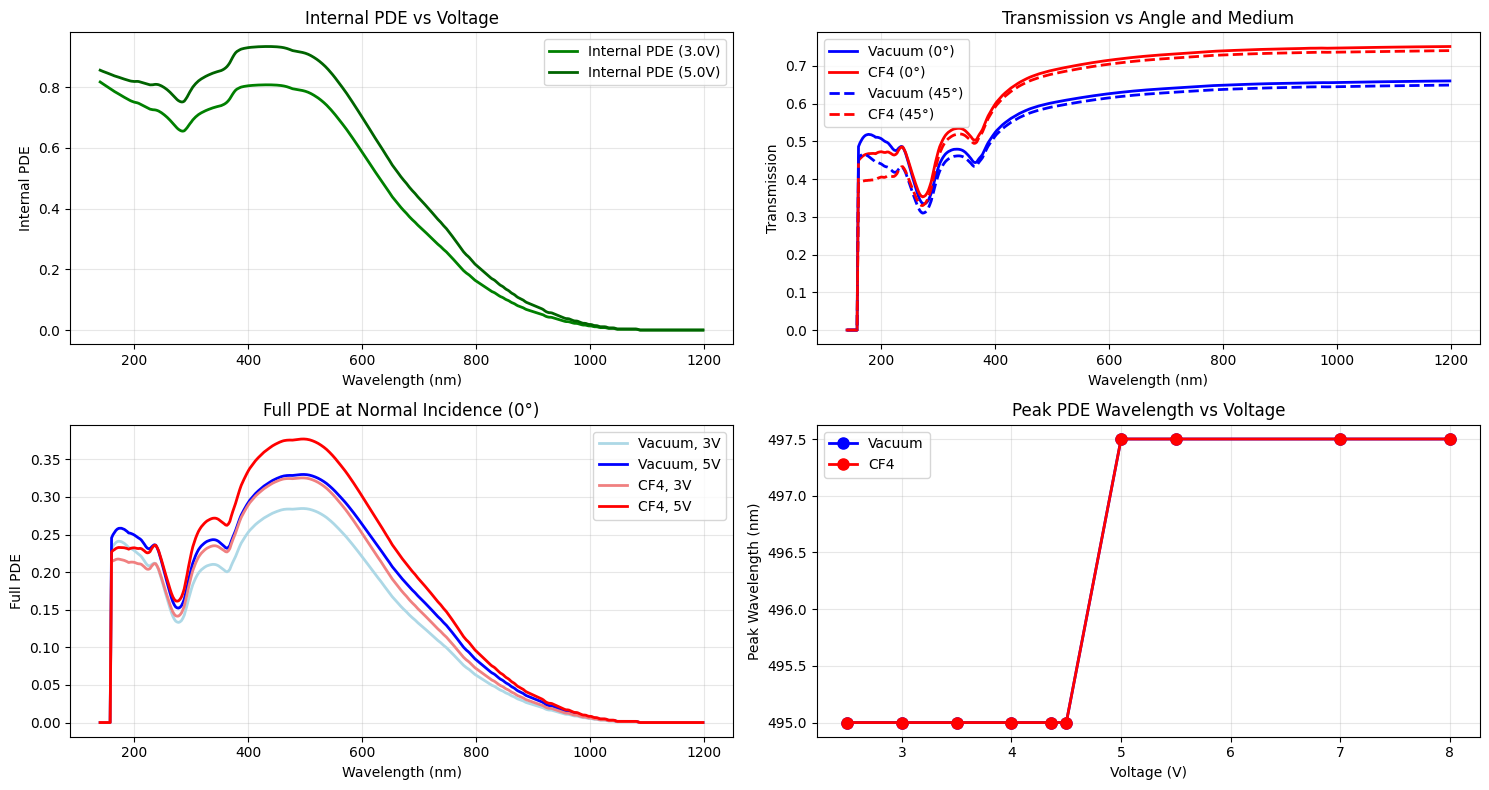

Device: HPK-VUV4_noWindow_17nmOxide_defaultData_globalPar_145K_june12
Fill Factor: 0.6
Oxide Thickness: 17.2 nm
Medium: cf4
Wavelength range: 140.0 - 1197.5 nm
Angle range: 0.0 - 87.5°
Voltage range: 2.5 - 8.0V


In [62]:
# Plot full PDE combining optics and internal PDE for both media, angles, and voltages

# Select specific angles and voltages to plot
angles_to_plot = [0, 45]  # degrees
voltages_to_plot = [3.0, 5.0]  # volts

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
axes = axes.flatten()

plot_idx = 0
for voltage in voltages_to_plot:
  for angle in angles_to_plot:
    ax = axes[plot_idx]
    
    # Get internal PDE for this voltage
    internal_pde = df_internal[df_internal['voltage'] == voltage]['internalPDE'].values
    
    # Get transmission values for this angle from both media
    transmission_vacuum = df[df['angle'] == angle]['transmission_vacuum'].values
    transmission_medium = df[df['angle'] == angle]['transmission_' + str(mediumProduction)].values
    
    # Calculate full PDE = Fill Factor * Transmission * Internal PDE
    full_pde_vacuum = FF1 * transmission_vacuum * internal_pde
    full_pde_medium = FF1 * transmission_medium * internal_pde
    
    # Plot the results
    ax.plot(wlenRange, full_pde_vacuum, 
            label=f'Vacuum, {angle}°, {voltage}V', 
            linewidth=2, 
            color='blue' if angle == 0 else 'darkblue',
            linestyle='-' if voltage == voltages_to_plot[0] else '--')
    
    ax.plot(wlenRange, full_pde_medium, 
            label=f'{mediumProduction.upper()}, {angle}°, {voltage}V', 
            linewidth=2, 
            color='red' if angle == 0 else 'darkred',
            linestyle='-' if voltage == voltages_to_plot[0] else '--')
    
    ax.set_xlabel('Wavelength (nm)')
    ax.set_ylabel('Full PDE')
    ax.set_title(f'Full PDE at {angle}° and {voltage}V')
    ax.legend()
    ax.grid(True, alpha=0.3)
    ax.set_xlim(150, 1000)
    
    plot_idx += 1

plt.tight_layout()
plt.suptitle(f'Full PDE Comparison: {devName}', fontsize=14, y=1.02)
plt.show()

# Also create a summary plot showing the effect of each component
fig, axes = plt.subplots(2, 2, figsize=(15, 8))
ax1, ax2, ax3, ax4 = axes.flatten()

# Plot 1: Internal PDE comparison
ax1.plot(wlenRange, df_internal[df_internal['voltage'] == 3.0]['internalPDE'], 
         label='Internal PDE (3.0V)', color='green', linewidth=2)
ax1.plot(wlenRange, df_internal[df_internal['voltage'] == 5.0]['internalPDE'], 
         label='Internal PDE (5.0V)', color='darkgreen', linewidth=2)
ax1.set_xlabel('Wavelength (nm)')
ax1.set_ylabel('Internal PDE')
ax1.set_title('Internal PDE vs Voltage')
ax1.legend()
ax1.grid(True, alpha=0.3)

# Plot 2: Transmission comparison
ax2.plot(wlenRange, df[df['angle'] == 0]['transmission_vacuum'], 
         label='Vacuum (0°)', color='blue', linewidth=2)
ax2.plot(wlenRange, df[df['angle'] == 0]['transmission_' + str(mediumProduction)], 
         label=f'{mediumProduction.upper()} (0°)', color='red', linewidth=2)
ax2.plot(wlenRange, df[df['angle'] == 45]['transmission_vacuum'], 
         label='Vacuum (45°)', color='blue', linewidth=2, linestyle='--')
ax2.plot(wlenRange, df[df['angle'] == 45]['transmission_' + str(mediumProduction)], 
         label=f'{mediumProduction.upper()} (45°)', color='red', linewidth=2, linestyle='--')
ax2.set_xlabel('Wavelength (nm)')
ax2.set_ylabel('Transmission')
ax2.set_title('Transmission vs Angle and Medium')
ax2.legend()
ax2.grid(True, alpha=0.3)

# Plot 3: Full PDE at normal incidence
internal_pde_3v = df_internal[df_internal['voltage'] == 3.0]['internalPDE'].values
internal_pde_5v = df_internal[df_internal['voltage'] == 5.0]['internalPDE'].values
trans_vac_0deg = df[df['angle'] == 0]['transmission_vacuum'].values
trans_med_0deg = df[df['angle'] == 0]['transmission_' + str(mediumProduction)].values

ax3.plot(wlenRange, FF1 * trans_vac_0deg * internal_pde_3v, 
         label='Vacuum, 3V', color='lightblue', linewidth=2)
ax3.plot(wlenRange, FF1 * trans_vac_0deg * internal_pde_5v, 
         label='Vacuum, 5V', color='blue', linewidth=2)
ax3.plot(wlenRange, FF1 * trans_med_0deg * internal_pde_3v, 
         label=f'{mediumProduction.upper()}, 3V', color='lightcoral', linewidth=2)
ax3.plot(wlenRange, FF1 * trans_med_0deg * internal_pde_5v, 
         label=f'{mediumProduction.upper()}, 5V', color='red', linewidth=2)
ax3.set_xlabel('Wavelength (nm)')
ax3.set_ylabel('Full PDE')
ax3.set_title('Full PDE at Normal Incidence (0°)')
ax3.legend()
ax3.grid(True, alpha=0.3)

# Plot 4: Peak wavelength analysis
peak_wavelengths_vac = []
peak_wavelengths_med = []
for voltage in voltages:
  internal_pde = df_internal[df_internal['voltage'] == voltage]['internalPDE'].values
  full_pde_vac = FF1 * trans_vac_0deg * internal_pde
  full_pde_med = FF1 * trans_med_0deg * internal_pde
  
  peak_idx_vac = np.argmax(full_pde_vac)
  peak_idx_med = np.argmax(full_pde_med)
  
  peak_wavelengths_vac.append(wlenRange[peak_idx_vac])
  peak_wavelengths_med.append(wlenRange[peak_idx_med])

ax4.plot(voltages, peak_wavelengths_vac, 'o-', label='Vacuum', color='blue', linewidth=2, markersize=8)
ax4.plot(voltages, peak_wavelengths_med, 'o-', label=f'{mediumProduction.upper()}', color='red', linewidth=2, markersize=8)
ax4.set_xlabel('Voltage (V)')
ax4.set_ylabel('Peak Wavelength (nm)')
ax4.set_title('Peak PDE Wavelength vs Voltage')
ax4.legend()
ax4.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f"Device: {devName}")
print(f"Fill Factor: {FF1}")
print(f"Oxide Thickness: {ttGood} nm")
print(f"Medium: {mediumProduction}")
print(f"Wavelength range: {wlenRange[0]} - {wlenRange[-1]} nm")
print(f"Angle range: {angles[0]} - {angles[-1]}°")
print(f"Voltage range: {voltages[0]} - {voltages[-1]}V")